# New Reference Chain Validation / 新增传导链检验

## tl;dr

31 chains reviewed: **10 partial numerical diagnostics,4 case/condition reviews,17 data gaps**.
Seven chain-specific event views reuse five signals; five views meet the screening gate, representing
only three distinct signals. Eight association specifications cover seven chains.
**No newly added chain is fully validated.** This is not a finding that all mechanisms are false.

The strongest primary level/throughput associations require caution: MBSD levels rho0.879 weaken
to0.414 in changes; auction supply/total settlement rho0.578 weakens under month-effect OLS
(HAC p0.204). These are proxies, not service-specific losses or disruptions.

中文：31条均有核对记录，10条做了部分数值检验；没有把代理变量通过写成整链验证。

## Context & Methods

Definition v3; report date2026-10-21. Plan: `analysis_plan.json`; any source repair:
`data_quality_amendment.json`. Old October16 definitions/results remain unchanged.

### Key Assumptions

- Same-quarter transmission associations are primary; next-quarter pairs are secondary descriptive
  lead-lag relationships, not real-time forecasting given publication delays/revisions.
- Legacy event/association gates retained. Quarterly paired4-quarter blocks, monthly12-month blocks,
  2,000 resamples, seed20261016. Six primary specifications receive BH correction.
- Named-member, service and process relevance cannot be proved by aggregate proxies.
- Framework remains **S times V**; no separate E multiplier, fabricated missing V or calibrated score.
- Exploratory extension after old results were known; not preregistered, no blind holdout.
- Current rulebooks document possible mechanisms, not historical rule versions or incident outcomes.

Interpret inferential intervals conditionally on the frozen public data and chosen block design.

## Data

Frozen market snapshot: series-specific October9/13 cutoffs. PQD outcomes:2020Q4–2026Q2.
New OFR final data end2026-06-30. Treasury auctions filtered to completed records through
2026-10-20; complete-month tests end2026-09. Fed Financial Accounts: September11 release,
flows through2026Q2. New PQD XLSX fields omit2024Q4; financial notes supply its unsettled
outcome explicitly, without inventing the missing cleared-notional observation.

All inputs, hashes, raw downloads and exact paired rows accompany this notebook.
No network calls are made below. Install packages in `requirements.txt` and run from this folder.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
assert (root / "inputs/chain_registry_v3.json").exists(), "Run this notebook from its containing folder."
sys.path.insert(0, str(root / "src"))
from run_tests import run, check_inputs
check_inputs()
print("Frozen source hashes verified. Definitions: v3; newly added chains: 31.")
pd.set_option("display.max_colwidth", 58)
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11, "axes.spines.top":False,
                    "axes.spines.right":False, "figure.facecolor":"white", "axes.facecolor":"white"})

Frozen source hashes verified. Definitions: v3; newly added chains: 31.


### Recompute from frozen sources

The following cell rebuilds PQD cell extracts, Fed flows, auction filters, signals and statistics.
Financial guarantee-note reconciliation is frozen with its source PDFs/pages and can separately
be rebuilt with `src/extract_financial_guarantees.py`.

In [2]:
association_results, event_results = run()
from build_delivery import main as build_delivery
build_delivery()
coverage = pd.read_csv(root / "results/series_coverage.csv")
display(coverage[["series_id", "n", "first", "last"]])

                      test_id                     role  lag   n     rho  coefficient_bp  ci_low  ci_high  bh_q_primary
                  GCF_FUNDING                  primary    0 246     NaN           0.021 -1.3275   1.3695        0.9757
                      MMF_GCF                  primary    0  31  0.1153             NaN -0.1783   0.4968        0.6441
                      MMF_GCF    secondary_next_period    1  31 -0.1480             NaN -0.3978   0.1705           NaN
                 TRIPARTY_GCF      supplementary_proxy    0  97  0.0987             NaN -0.0685   0.2241           NaN
                 TRIPARTY_GCF    secondary_next_period    1  97  0.3193             NaN  0.2079   0.4858           NaN
                 CROSS_MARGIN                  primary    0  22  0.4083             NaN -0.0143   0.7643        0.1185
                 CROSS_MARGIN    secondary_next_period    1  22  0.4639             NaN -0.1220   0.7153           NaN
                  AUCTION_GSD                  p

,series_id,n,first,last
0,funding,2004,2018-10-01,2026-10-13
1,ust10_abs_change,2193,2018-01-03,2026-10-09
2,vix,2240,2018-01-02,2026-10-13
3,cp_bill_spread,1555,2018-01-02,2026-10-13
4,triparty_withdrawal,2110,2018-01-09,2026-06-30
5,gcf_volume,2034,2018-05-07,2026-06-30
6,triparty_volume,2115,2018-01-02,2026-06-30


### Inspect the material source repair

Early PQD23.2.1 values for2020Q4–2021Q3 were1,000times smaller than the FICC guarantee-note
table in billions of USD. The raw values remain preserved; financial-note values replace the
misaligned outcome at its stated precision. This repair changes no event window or threshold.
2024Q4 is a genuine financial-note observation, not a synthesized spreadsheet cell.

In [3]:
reconciliation = pd.read_csv(root / "data/financial_guarantee_reconciliation.csv")
flagged = reconciliation[~reconciliation.within_rounding_tolerance]
display(flagged[["quarter","entity","pqd_as_reported","financial_usd","financial_to_pqd_ratio","source_file","page"]])
activity_repair = pd.read_csv(root / "data/mbsd_cleared_notional_reconciliation.csv")
display(activity_repair[activity_repair.conversion_factor.ne(1)]
        [["quarter","raw_pqd23_1_2","chosen_usd","monthly_total_usd","observed_treasury_days","independent_daily_mean_usd"]])
auction_audit = json.loads((root / "results/auction_filter_audit.json").read_text())
display(pd.Series({k:auction_audit[k] for k in ["response_records","selected_records","server_date_predicate_ignored","last_full_month"]}))

,quarter,entity,pqd_as_reported,financial_usd,financial_to_pqd_ratio,source_file,page
0,2020Q4,GSD,1.201000e+09,1.201000e+12,1000.0,FICC_Annual_2020_2019.pdf,22
1,2020Q4,MBSD,6.290000e+08,6.290000e+11,1000.0,FICC_Annual_2020_2019.pdf,22
2,2021Q1,GSD,1.096000e+09,1.096000e+12,1000.0,FICC_Q1_2021.pdf,14
3,2021Q1,MBSD,6.270000e+08,6.270000e+11,1000.0,FICC_Q1_2021.pdf,14
4,2021Q2,GSD,1.089000e+09,1.089000e+12,1000.0,FICC_Q2_2021.pdf,14
5,2021Q2,MBSD,4.580000e+08,4.580000e+11,1000.0,FICC_Q2_2021.pdf,14
6,2021Q3,GSD,1.053000e+09,1.053000e+12,1000.0,FICC_Q3_2021.pdf,14
7,2021Q3,MBSD,4.590000e+08,4.590000e+11,1000.0,FICC_Q3_2021.pdf,14
32,2024Q4,GSD,NaN,2.818000e+12,NaN,FICC_Annual_2024_2023.pdf,23
33,2024Q4,MBSD,NaN,4.550000e+11,NaN,FICC_Annual_2024_2023.pdf,23


,quarter,raw_pqd23_1_2,chosen_usd,monthly_total_usd,observed_treasury_days,independent_daily_mean_usd
3,2021Q3,357108.0,3.571080e+11,2.285490e+13,64,3.571079e+11
7,2022Q3,317483.0,3.174830e+11,2.031890e+13,64,3.174829e+11


response_records                   11158
selected_records                    3594
server_date_predicate_ignored       True
last_full_month                  2026-09
dtype: object

## Results

### Event signal screening

PASS_COMPONENT means the signal meets the old retrospective event rule. It does **not** show
that the named service suffered a disruption. Funding/VIX observations are shared, not independent
experiments. Non-event alert share is a proxy, not a measured false-positive rate.

In [4]:
display(event_results[["chain_id","events_hit","events_available","non_event_alert_proxy","status"]].round(3))

,chain_id,events_hit,events_available,non_event_alert_proxy,status
0,FICC-GSD-05,3,3,0.124,PASS_COMPONENT
1,FICC-GSD-07,0,4,0.104,FAIL_COMPONENT
2,FICC-GSD-09,3,3,0.122,PASS_COMPONENT
3,ECS-NSCC-05,3,4,0.077,PASS_COMPONENT
4,ECS-NSCC-09,2,2,0.121,PASS_COMPONENT
5,ECS-DTC-01,1,2,0.101,FAIL_COMPONENT
6,ECS-DTC-06,3,4,0.077,PASS_COMPONENT


### Associations and internal diagnostics

The main table below includes primary, separately specified supplementary and internal-diagnostic
rows. GCF's daily coefficient is in basis points; other rows are rank correlations. Ordinary p/BH
are supplementary; dependence-aware intervals/HAC and source scope remain essential.

In [5]:
main_results = association_results[association_results.lag.eq(0) & association_results.role.isin(["primary","internal_diagnostic","supplementary_proxy"])]
display(main_results[["test_id","role","n","rho","coefficient_bp","ci_low","ci_high","bh_q_primary"]].round(4))
display(association_results[association_results.role.eq("primary") & association_results.frequency.eq("Q")]
        [["test_id","rho","rho_changes","rho_earlier","rho_later"]].round(3))
display(association_results[association_results.role.eq("data_quality_sensitivity")]
        [["test_id","n","rho","ci_low","ci_high","rho_changes"]].round(3))

,test_id,role,n,rho,coefficient_bp,ci_low,ci_high,bh_q_primary
0,GCF_FUNDING,primary,246,NaN,0.021,-1.3275,1.3695,0.9757
1,MMF_GCF,primary,31,0.1153,NaN,-0.1783,0.4968,0.6441
3,TRIPARTY_GCF,supplementary_proxy,97,0.0987,NaN,-0.0685,0.2241,NaN
5,CROSS_MARGIN,primary,22,0.4083,NaN,-0.0143,0.7643,0.1185
7,AUCTION_GSD,primary,104,0.5776,NaN,0.4506,0.6883,0.0000
9,TBA_PIPELINE,primary,22,0.8792,NaN,0.6379,0.9355,0.0000
11,CONCENTRATION,internal_diagnostic,22,-0.3529,NaN,-0.7253,0.2577,NaN
13,SLD_LIQUIDITY,primary,23,0.3261,NaN,-0.0826,0.7714,0.1933


,test_id,rho,rho_changes,rho_earlier,rho_later
1,MMF_GCF,0.115,0.380,0.105,0.143
5,CROSS_MARGIN,0.408,0.186,0.441,-0.147
9,TBA_PIPELINE,0.879,0.414,0.871,0.257
13,SLD_LIQUIDITY,0.326,-0.108,0.512,-0.029


,test_id,n,rho,ci_low,ci_high,rho_changes
15,TBA_PIPELINE_EXCLUDE_REPAIRED,20,0.865,0.573,0.947,0.268


### Quarterly correlation intervals

Each point is a declared same-quarter association. Lines are95% paired moving-block bootstrap
intervals using four consecutive quarters. The dashed0.3 line is the legacy component threshold;
the lower bound also must exceed zero. All displayed routes still have proxy/process-data gaps.
Sources: frozen PQD/market inputs, new Fed Z1 archive and exact `data/*_pairs.csv` files.

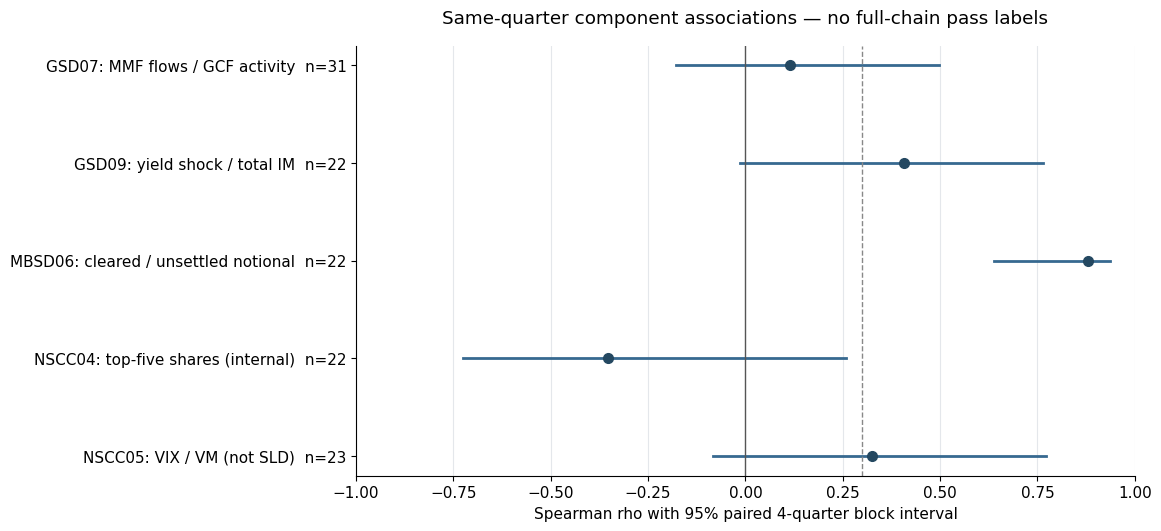

In [6]:
q = main_results[main_results.frequency.eq("Q")].copy()
labels = {"MMF_GCF":"GSD07: MMF flows / GCF activity", "CROSS_MARGIN":"GSD09: yield shock / total IM",
          "TBA_PIPELINE":"MBSD06: cleared / unsettled notional", "CONCENTRATION":"NSCC04: top-five shares (internal)",
          "SLD_LIQUIDITY":"NSCC05: VIX / VM (not SLD)"}
fig, ax = plt.subplots(figsize=(11.5,5.2), layout="constrained")
for i, (_, row) in enumerate(q.iterrows()):
    ax.plot([row.ci_low,row.ci_high],[i,i],color="#376990",linewidth=2)
    ax.plot(row.rho,i,"o",color="#244861",markersize=7)
ax.set_yticks(range(len(q)), [labels[r.test_id]+f"  n={int(r.n)}" for _,r in q.iterrows()])
ax.invert_yaxis(); ax.axvline(0,color="#555555",linewidth=1);ax.axvline(.3,color="#888888",linestyle="--",linewidth=1)
ax.set_xlim(-1,1);ax.set_xlabel("Spearman rho with 95% paired 4-quarter block interval")
ax.set_title("Same-quarter component associations — no full-chain pass labels",pad=16)
ax.grid(axis="x",color="#e4e7eb");ax.set_axisbelow(True)
fig.savefig(root/"figures/quarterly_components.png",dpi=170,bbox_inches="tight")
plt.show()

### MBSD: levels versus changes

Strong association in levels is not stable transmission evidence. The change plot uses only
consecutive quarters; it never bridges missing2024Q4 cleared notional. Cleared notional is a
daily average flow, while unsettled notional is a quarter-end stock; the axes state those units.
Neither measure identifies future TBA settlement tenors or an independent external event.

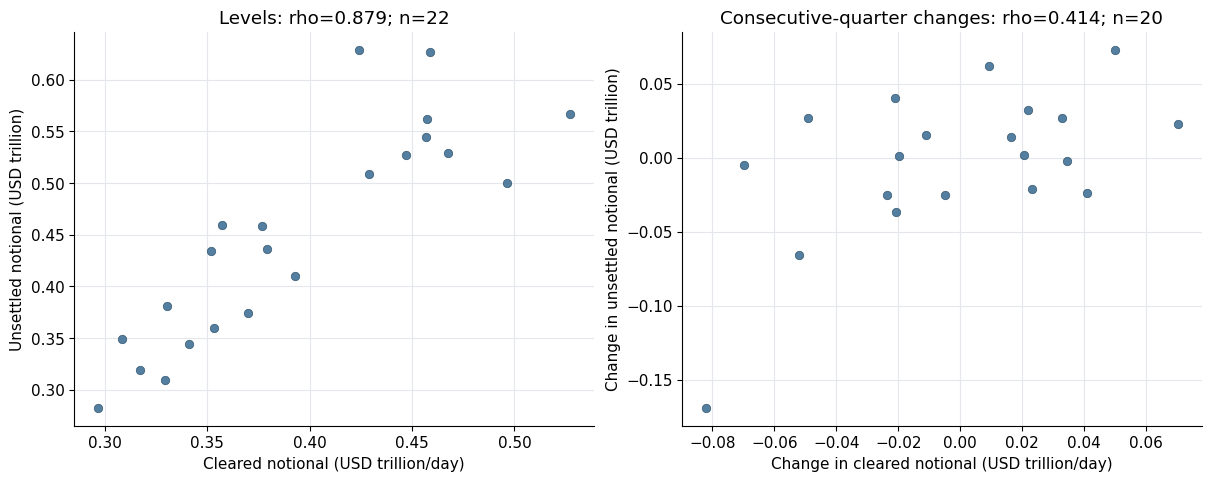

In [7]:
pairs=pd.read_csv(root/"data/TBA_PIPELINE_lag0_pairs.csv")
pairs.index=pd.PeriodIndex(pairs.period,freq="Q")
difference=pairs[["x","y"]].diff().where(pd.Series(np.r_[False,np.diff(pairs.index.asi8)==1],index=pairs.index),axis=0).dropna()
from scipy.stats import spearmanr
fig,axs=plt.subplots(1,2,figsize=(12,4.7),layout="constrained")
for ax,data,title in [(axs[0],pairs,"Levels"),(axs[1],difference,"Consecutive-quarter changes")]:
    ax.scatter(data.x/1e12,data.y/1e12,color="#376990",s=37,alpha=.85,edgecolors="#244861",linewidth=.5)
    coefficient=spearmanr(data.x,data.y).statistic
    ax.set_title(f"{title}: rho={coefficient:.3f}; n={len(data)}")
    ax.set_xlabel("Cleared notional (USD trillion/day)" if title=="Levels" else "Change in cleared notional (USD trillion/day)")
    ax.set_ylabel("Unsettled notional (USD trillion)" if title=="Levels" else "Change in unsettled notional (USD trillion)")
    ax.grid(color="#e4e7eb");ax.set_axisbelow(True)
fig.savefig(root/"figures/mbsd_levels_changes.png",dpi=170,bbox_inches="tight")
plt.show()

### Throughput robustness

Auction supply and aggregate GSD settlement changes have a positive rank association. The
separately declared regression with month effects has an interval crossing zero. This is
weaker evidence after seasonality control, not proof that auctions disrupt settlement.

In [8]:
display(pd.Series(json.loads((root/"results/auction_seasonality_robustness.json").read_text())))
status=pd.read_csv(root/"results/new_chain_status_EN.csv")
display(status[["chain_id","work_status","full_chain_status"]])
assert len(status)==31 and not status.full_chain_validated.any()
print("Full chain validation: 0; do not interpret missing evidence as a failed or safe business.")

n                                                                         104
coefficient                                                          2.198913
hac_p                                                                0.203538
ci                                   [-1.1905218619975741, 5.588348061189436]
scope                   aggregate throughput, not auction-specific disruption
seasonality                                    calendar-month dummy variables
full_chain_validated                                                    False
dtype: object

,chain_id,work_status,full_chain_status
0,ECS-NSCC-04,Partial numerical tests,Not yet validated (not a blanket failure)
1,FICC-MBSD-02,Not run: specific data missing,Not yet validated (not a blanket failure)
2,FICC-MBSD-03,Not run: specific data missing,Not yet validated (not a blanket failure)
3,FICC-GSD-05,Partial numerical tests,Not yet validated (not a blanket failure)
4,FICC-GSD-07,Partial numerical tests,Not yet validated (not a blanket failure)
5,FICC-MBSD-04,Case/condition review only,Not yet validated (not a blanket failure)
6,FICC-MBSD-05,Not run: specific data missing,Not yet validated (not a blanket failure)
7,FICC-GSD-09,Partial numerical tests,Not yet validated (not a blanket failure)
8,FICC-GSD-10,Partial numerical tests,Not yet validated (not a blanket failure)
9,FICC-MBSD-06,Partial numerical tests,Not yet validated (not a blanket failure)


Full chain validation: 0; do not interpret missing evidence as a failed or safe business.


## Takeaways

- Prioritize direct auction/GSD outcomes, forward-TBA maturity buckets and NSCC SLD collections.
- Obtain participant-identified incident/obligation records for operational and member-specific routes.
- Historical Lehman/Carter body URLs are unavailable; indexed excerpts are limited leads only.
- Keep MMF flows distinct from CCIT withdrawals, VM from SLD, SFTR from NSCC SFT clearing,
  and external market stress from DTC/EPN service disruption.
- Shared source data are collected once and linked to multiple chains; shared views do not add
  independent observations. No causal, predictive or calibrated scoring claim is made.

中英文逐链明细与缺项：`Concise_Test_Summary_CN.md`、`Concise_Test_Summary_EN.md`。
Exact evidence: `results/source_register.json`, `fetch_manifest.json`, `input_manifest.json`,
`data/new_pqd_cell_evidence.csv`, `data/financial_guarantee_reconciliation.csv`.

Methods references: October16 legacy plan; Quant-tech statistical-inference notes on dependence
and rare events; SciPy Spearman and statsmodels HAC APIs. Public sources: [Federal Reserve Z1](https://www.federalreserve.gov/releases/z1/20260911/z1_csv_files.zip),
[OFR](https://data.financialresearch.gov/), [TreasuryDirect](https://www.treasurydirect.gov/legal-information/developers/web-api-security/),
[DTCC disclosures](https://www.dtcc.com/legal/policy-and-compliance) and [current rules](https://www.dtcc.com/legal/rules-and-procedures).